# 04. 탐색적 데이터 분석

**입력**: `dataSets/starfield_analysis.csv`, `dataSets/reviews_for_embedding.csv` (03에서 확정한 분석 대상 70,915건)
**출력**: `out/04_긍정률.png`, `out/04_상관.png`, `out/04_언어별_긍정률.png`

순서: ① 추천/비추천 비율 → ② 군집에 쓸 변수의 기술통계 → ③ 변수 선정을 위한 상관·VIF → ④ 언어별 긍정률

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)                                   # 폰트 파일 등록
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()   # 파일 안의 폰트 이름을 읽어 지정
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 페르소나 색 (모든 노트북 공통)
C_POS = '#4C72B0'   # 긍정
C_NEG = '#C44E52'   # 부정

In [2]:
# 원본에서 분석 대상(03에서 저장한 id)만 남긴다
meta = pd.read_csv('dataSets/starfield_analysis.csv', low_memory=False)
pop = pd.read_csv('dataSets/reviews_for_embedding.csv', usecols=['steamid'])
df = meta.merge(pop, on='steamid', how='inner')
print('분석 대상', len(df), '건')

분석 대상 70915 건


## 1. 추천/비추천 비율

추천 40542 건 ( 57.2 % ) / 비추천 30373 건 ( 42.8 % )


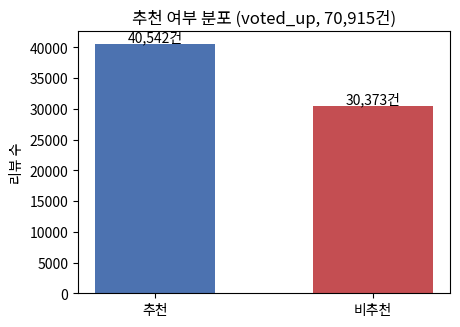

In [3]:
n_pos = (df['voted_up'] == True).sum()
n_neg = (df['voted_up'] == False).sum()
print('추천', n_pos, '건 (', round(n_pos / len(df) * 100, 1), '% ) / 비추천', n_neg, '건 (', round(n_neg / len(df) * 100, 1), '% )')

fig, ax = plt.subplots(figsize=(4.8, 3.4))
bars = ax.bar(['추천', '비추천'], [n_pos, n_neg], color=[C_POS, C_NEG], width=0.55)
ax.bar_label(bars, labels=[f'{n_pos:,}건', f'{n_neg:,}건'])
ax.set_ylabel('리뷰 수')
ax.set_title('추천 여부 분포 (voted_up, 70,915건)')
fig.savefig('out/04_긍정률.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. 군집 변수 기술통계 (상한값 대체 후)

보유 게임·리뷰 수·플레이타임의 상위 0.5%는 봇이나 켜 놓고 방치한 계정이 만든 극단값이다.
그 값들을 상위 0.5% 지점의 값으로 바꾼다(윈저라이징). 업적 수는 최대 82가 "완주"라는 진짜 신호라 바꾸지 않는다.
같은 처리를 06(군집)과 07(플레이시간)에서도 쓴다.

In [4]:
FEATURES = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review']   # 군집 변수 4개
WINSORIZE = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'playtime_forever_min']

for col in WINSORIZE:
    cap = df[col].quantile(0.995)            # 상위 0.5% 지점의 값
    n_over = (df[col] > cap).sum()
    df[col] = df[col].clip(upper=cap)         # cap보다 큰 값은 cap으로 바꾼다
    print(col, '상한', round(cap, 2), '/ 대체', n_over, '건')

games_owned 상한 3466.72 / 대체 355 건
num_reviews 상한 281.43 / 대체 355 건
playtime_at_review_min 상한 38822.02 / 대체 355 건
playtime_forever_min 상한 85909.87 / 대체 355 건


In [5]:
# 기술통계표: 행 = 통계량, 열 = 변수
desc = pd.DataFrame({
    'min': df[FEATURES].min(),
    'max': df[FEATURES].max(),
    'mean': df[FEATURES].mean(),
    'median': df[FEATURES].median(),
    'std': df[FEATURES].std(),
    'skew': df[FEATURES].skew(),
    'kurt': df[FEATURES].kurt(),
})
print(desc.round(2))
print()
print('세 변수는 왜도 3.5·첨도 16 이상으로 오른쪽 꼬리가 길다 → 로그변환. 업적 수는 왜도 1.1이지만 척도를 맞추려고 log1p.')

                        min       max     mean  median      std  skew   kurt
games_owned             1.0   3466.72   376.67   237.0   456.78  3.54  16.53
num_reviews             1.0    281.43    26.94    14.0    38.22  3.55  16.26
playtime_at_review_min  5.0  38822.02  3804.02  2286.0  5087.64  3.59  17.21
n_ach_at_review         0.0     82.00    14.67    10.0    12.89  1.07   0.54

세 변수는 왜도 3.5·첨도 16 이상으로 오른쪽 꼬리가 길다 → 로그변환. 업적 수는 왜도 1.1이지만 척도를 맞추려고 log1p.


## 3. 군집 변수 선정 — 상관과 VIF

후보 변수 중 상관이 0.8 이상인 쌍은 하나만 남긴다. 변수가 심하게 치우쳐 있어서 순위 기반(스피어만) 상관을 쓴다.
리뷰 뒤에 바뀌는 "최종" 변수(stage_final, n_ach_total, playtime_forever)는 리뷰 시점 특성이 아니므로 군집 변수에서 뺀다.

스피어만 상관 0.8 이상인 쌍
  n_ach_at_review - stage_at_review : 0.847
  n_ach_total - stage_final : 0.855


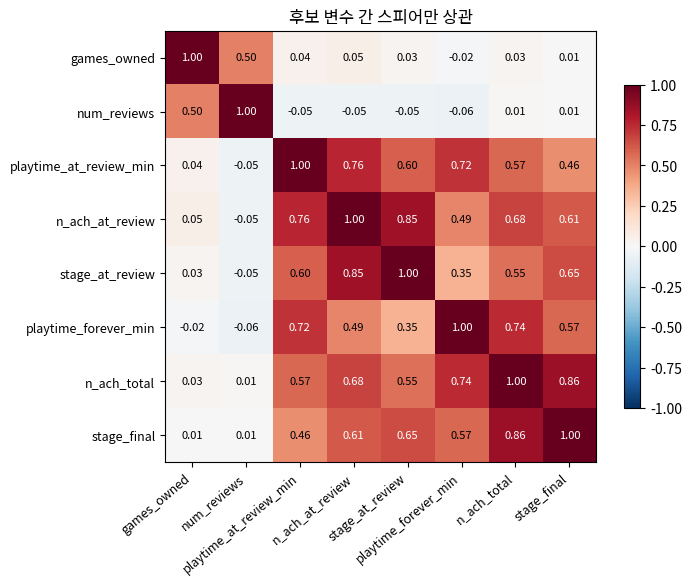

In [6]:
CANDIDATES = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review', 'stage_at_review',
              'playtime_forever_min', 'n_ach_total', 'stage_final']
corr = df[CANDIDATES].corr(method='spearman')

print('스피어만 상관 0.8 이상인 쌍')
for i in range(len(CANDIDATES)):
    for j in range(i + 1, len(CANDIDATES)):
        a = CANDIDATES[i]
        b = CANDIDATES[j]
        if corr.loc[a, b] >= 0.8:
            print(' ', a, '-', b, ':', round(corr.loc[a, b], 3))

# 상관 히트맵
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(CANDIDATES)))
ax.set_xticklabels(CANDIDATES, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(CANDIDATES)))
ax.set_yticklabels(CANDIDATES, fontsize=9)
for i in range(len(CANDIDATES)):
    for j in range(len(CANDIDATES)):
        value = corr.iloc[i, j]
        text_color = 'white' if abs(value) > 0.6 else 'black'
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8, color=text_color)
fig.colorbar(im, ax=ax, shrink=0.75)
ax.set_title('후보 변수 간 스피어만 상관')
fig.savefig('out/04_상관.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
def vif(frame):
    """VIF(분산팽창계수). 변수 하나를 나머지 변수들로 회귀했을 때의 R²로 1/(1-R²)를 계산한다.
    10을 넘으면 다른 변수들과 너무 비슷해서(다중공선성) 문제가 된다."""
    result = {}
    for target in frame.columns:
        others = [c for c in frame.columns if c != target]
        X = frame[others].values
        X = np.column_stack([np.ones(len(X)), X])   # 절편 열 추가
        y = frame[target].values
        beta = np.linalg.lstsq(X, y, rcond=None)[0]   # 최소제곱 회귀계수
        predicted = X @ beta
        ss_res = ((y - predicted) ** 2).sum()
        ss_tot = ((y - y.mean()) ** 2).sum()
        r2 = 1 - ss_res / ss_tot
        result[target] = 1 / (1 - r2)
    return pd.Series(result)


print('후보 8개 변수 VIF (참고용 — 모두 10 미만)')
print(vif(df[CANDIDATES].astype(float)).sort_values(ascending=False).round(2))

# 군집 변수 4개는 로그변환·표준화 후 VIF
logged = df[FEATURES].astype(float).copy()
for col in ['games_owned', 'num_reviews', 'playtime_at_review_min']:
    logged[col] = np.log(logged[col])
logged['n_ach_at_review'] = np.log1p(logged['n_ach_at_review'])   # 0이 있어서 log1p
standardized = (logged - logged.mean()) / logged.std()
print()
print('군집 변수 4개 VIF (로그·표준화 후)')
print(vif(standardized).round(2))

후보 8개 변수 VIF (참고용 — 모두 10 미만)
n_ach_at_review           6.48
n_ach_total               5.53
stage_at_review           5.23
stage_final               4.55
playtime_at_review_min    2.74
playtime_forever_min      2.53
num_reviews               1.22
games_owned               1.21
dtype: float64

군집 변수 4개 VIF (로그·표준화 후)
games_owned               1.37
num_reviews               1.37
playtime_at_review_min    2.34
n_ach_at_review           2.35
dtype: float64


stage_at_review와 n_ach_at_review의 상관이 0.85로 높아 하나만 쓴다 — 값 범위가 0~82로 정보가 많은 업적 수를 택했다.

## 4. 언어별 긍정률

리뷰 100건 이상인 언어만 본다. 언어마다 긍정률이 35~81%로 다르므로 한 언어만 쓰면 표본이 치우친다 — 5장에서 다국어 모델을 쓰는 이유.

In [8]:
# 언어별로 리뷰 수와 긍정률을 계산한다
lang = df.groupby('language')['voted_up'].agg(['size', 'mean'])
lang.columns = ['n', '긍정률']
lang['긍정률'] = lang['긍정률'] * 100
lang = lang[lang['n'] >= 100].sort_values('긍정률')
print('리뷰 100건 이상 언어', len(lang), '개')
print(lang.round(1))

리뷰 100건 이상 언어 19 개
               n   긍정률
language              
koreana      610  35.2
schinese   15031  52.7
polish       737  56.2
english    42244  56.4
russian     1097  57.2
french      2259  59.6
ukrainian    201  61.2
japanese     330  62.4
tchinese     345  62.9
turkish      878  64.7
german      2964  65.1
czech        261  65.5
swedish      123  67.5
italian      533  70.7
spanish     1376  73.0
brazilian   1030  76.7
latam        242  77.7
dutch        157  77.7
hungarian    102  81.4


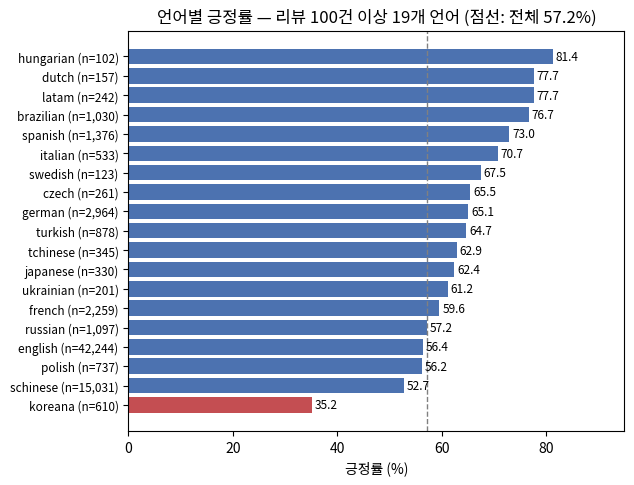

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
labels = []
colors = []
for name, n in zip(lang.index, lang['n']):
    labels.append(f'{name} (n={n:,})')
    if name == 'koreana':
        colors.append(C_NEG)   # 한국어만 빨간색으로 강조
    else:
        colors.append(C_POS)
bars = ax.barh(labels, lang['긍정률'], color=colors)
ax.bar_label(bars, fmt='%.1f', fontsize=8.5, padding=2)

overall = df['voted_up'].mean() * 100
ax.axvline(overall, ls='--', color='gray', lw=1)
ax.set_xlim(0, 95)
ax.set_xlabel('긍정률 (%)')
ax.set_title(f'언어별 긍정률 — 리뷰 100건 이상 {len(lang)}개 언어 (점선: 전체 {overall:.1f}%)')
ax.tick_params(axis='y', labelsize=8.5)
fig.savefig('out/04_언어별_긍정률.png', dpi=150, bbox_inches='tight')
plt.show()